In [198]:
# Libraries
# General libraries to be used
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from mne.io import concatenate_raws, read_raw_edf
from mne.channels import make_standard_montage


# Potential Approach 1
from sklearn.ensemble import RandomForestClassifier



# This is the dataset to train the model
from mne.datasets.sleep_physionet.age import fetch_data

In [199]:
# This turns all unnecessary outputs off to make outputs easier to read.
mne.set_log_level("warning")

## Constants

In [200]:
# Group by Awake, Light Sleep (2 and 3), Deep Sleep (3 and 4), and REM (R)
annotation_event_id = {
    "Sleep stage W": 1,
    "Sleep stage 1": 2,
    "Sleep stage 2": 2,
    "Sleep stage 3": 3,
    "Sleep stage 4": 3,
    "Sleep stage R": 4,
}

# We want to combine stages 3 and 4, and 1 and 2, to add a layer of abstraction for the user, and make classification easier

event_id = {
    "Awake": 1,
    "Light Sleep": 2,
    "Deep Sleep": 3,
    "REM Sleep": 4,
}

frequency_bands = {
    "delta": [0.5, 4.5],
    "theta": [4.5, 8.5],
    "beta": [8.5, 11.5],
    "alpha": [11.5, 15.5],
    "sigma": [15.5, 30.5],
}

# tmin and tmax represent when epochs should start / finish
tmin = 0.0
tmax = 30.0 # By default, I am setting tmax as 30.0 but this may need to be changed to take into account the total size of files as it may not be cleanly divisible by 30, which might create problems

## Loading Data

In [201]:
def load_data(subject_index, night):
    # Each participant has a subject number, and recording_number (indicating which night is shown)
    # Subject number indicates which subject out of the 74 is selected
    # All variables have the suffix local so they don't shadow global variable

    [subject_files] = fetch_data(subjects=[subject_index], recording=[night]) # Recording represents the night / session that is being loaded, 1st or 2nd

    raw_file_local = mne.io.read_raw_edf(
        subject_files[0], # 0 for the raw file, 1 for the histogram of the participant
        stim_channel="Event marker",
        infer_types=True,
        exclude=['horizontal', 'oro-nasal', 'submental', 'rectal'], # Not all channels in the data can be available to the user e.g. rectal temperature
        preload=True,
        verbose="error"
        )

    # Remove frequencies <0.5 and >30.0 as these are likely not from the participant / will not help the model
    raw_file_local.filter(l_freq=0.5, h_freq=30.0, method="iir") # Basic preprocessing

    # Reading and setting the annotations
    annotations_local = mne.read_annotations(subject_files[night])

    # Crop annotations subroutine
    sleep_start = annotations_local[1]["onset"] - 30 * 4 * 60
    sleep_end = annotations_local[-2]["onset"] + 30 * 4 * 60
    annotations_local.crop(sleep_start, sleep_end)

    raw_file_local.set_annotations(annotations_local)


    return raw_file_local

In [202]:
def crop_annotations(raw_file, annotations):
    # Cropping 30 minutes before and after sleeping
    # This may need to change depending on the distribution of classes

    sleep_start = annotations[1]["onset"] - 30 * 60
    sleep_end = annotations[-2]["onset"] + 30 * 60

    annotations.crop(sleep_start, sleep_end)
    raw_file.set_annotations(annotations)

In [203]:
def create_events(raw_file_local):
    # Normally, mne.events_from_annotations returns a tuple so the underscore in "events, _" ensures that only the events is saved to the variable
    events_local, _ = mne.events_from_annotations(raw_file_local, event_id=annotation_event_id, chunk_duration=30.0)

    # Create a dictionary linking the number of events to a label
    event_id_local = dict(awake=1, light_sleep=2, deep_sleep=3, rem=4)

    return events_local, event_id_local




In [204]:
def create_epochs(raw_file_local, events_local, event_id_local):

    epochs_local = mne.Epochs(
        raw_file_local,
        events = events_local,
        event_id = event_id_local,
        tmin = tmin, # Set as 0.0
        tmax = tmax, # Set as 30.0
        proj = True,
        picks=['Fpz-Cz', 'Pz-Oz'],  # Event marker not included otherwise the model may be fed the true sleep stage
        baseline = None,
        preload = True,
    )


    epochs_train_local = epochs_local.copy().crop(tmin=0.0, tmax=30.0) # Would need to find out if 0 - 30 is an appropriate crop, and no crop may be needed at all

    labels_local = epochs_local.events[0:len(epochs_local), -1]
    print("Event labels array:")
    print(labels_local)

    return epochs_local, epochs_train_local, labels_local


## Visualising Data

In [205]:
# This is used to visualise and gain information about the PSD for each stage
def psd_plot(samples):
    print(samples)
    plt.close("all")
    samples.compute_psd(method='multitaper', fmin=0.5, fmax=50).plot()
    plt.show()

In [206]:
def load_histogram(subject_index, night):
    [subject_files] = fetch_data(subjects=[subject_index], recording=[night]) # Recording represents the night / session that is being loaded, 1st or 2nd

    raw_file = mne.io.read_raw_edf(
        subject_files[1], # 0 for the raw file, 1 for the histogram of the participant
        stim_channel="Event marker",
        infer_types=True,
        exclude='bads', # Not all channels can be available to the user e.g. rectal temperature
        preload=True,
        verbose="error"
        )

    # FIND OUT HOW TO PLOT HISTOGRAM



# Main program

Raw file loaded
Events created from raw file
Event labels array:
[1 1 1 ... 1 1 1]
Epochs created


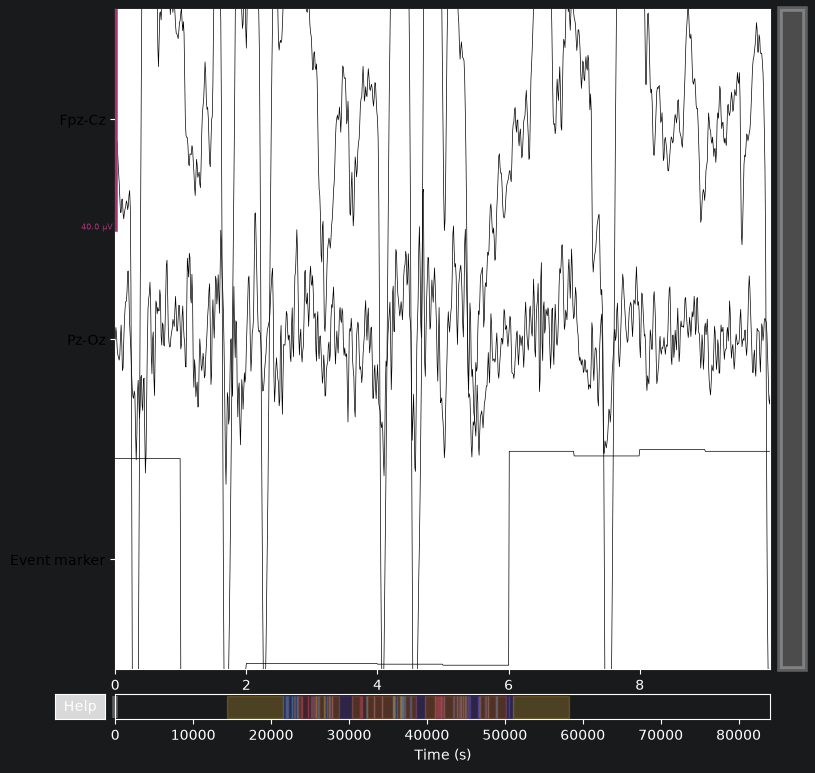

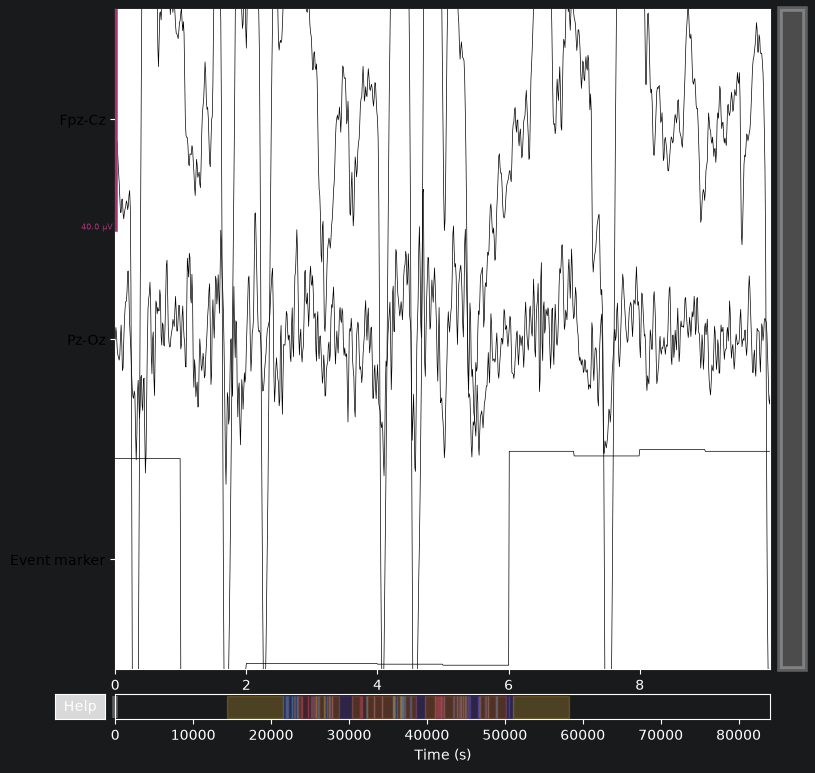

In [223]:
raw_file = load_data(1, 1)
print("Raw file loaded")

# Insert crop annotations subroutine

events, event_id = create_events(raw_file)
print("Events created from raw file")

epochs, epochs_train, labels = create_epochs(raw_file, events, event_id)
print("Epochs created")

raw_file.plot()

## Information about data types

In [208]:
raw_file.info



<Info | 8 non-empty values
 bads: []
 ch_names: Fpz-Cz, Pz-Oz, Event marker
 chs: 2 EEG, 1 Stimulus
 custom_ref_applied: False
 highpass: 0.5 Hz
 lowpass: 30.0 Hz
 meas_date: 1989-04-24 16:13:00 UTC
 nchan: 3
 projs: []
 sfreq: 100.0 Hz
 subject_info: <subject_info | his_id: X, sex: 2, first_name: Female, last_name: 33yr>
>

In [209]:
print(raw_file.ch_names)

['Fpz-Cz', 'Pz-Oz', 'Event marker']


In [210]:
print(annotations)

<Annotations | 153 segments: Sleep stage 1 (24), Sleep stage 2 (40), Sleep ...>


In [211]:
#print(picks)

Do I need picks????

In [212]:
print(event_id)

{'awake': 1, 'light_sleep': 2, 'deep_sleep': 3, 'rem': 4}


In [213]:
print(events)
print(len(events))
print(events.shape)

[[2343000       0       1]
 [2346000       0       1]
 [2349000       0       1]
 ...
 [5937000       0       1]
 [5940000       0       1]
 [5943000       0       1]]
1201
(1201, 3)


Events is an array 3 by 2802 as there are 2802 samples

In [214]:
annotations

<Annotations | 153 segments: Sleep stage 1 (24), Sleep stage 2 (40), Sleep ...>

In [215]:
epochs

<Epochs | 1201 events (all good), 0 – 30 s (baseline off), ~55.0 MiB, data loaded,
 'awake': 548
 'light_sleep': 308
 'deep_sleep': 220
 'rem': 125>

There are unbalanced class distributions for the different stages so some of the awake annotations should be cropped, idealy to around 671, the next highest stage
awake: 1855
deep_sleep: 105
light_sleep: 671
rem: 170

# Creating Features

Explain why multitaper is the best method!!

/var/folders/n_/8b4bszmd5vsdmpldt1bzw7jr0000gn/T/ipykernel_59824/1854888808.py:2: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  psd_of_epochs.plot()


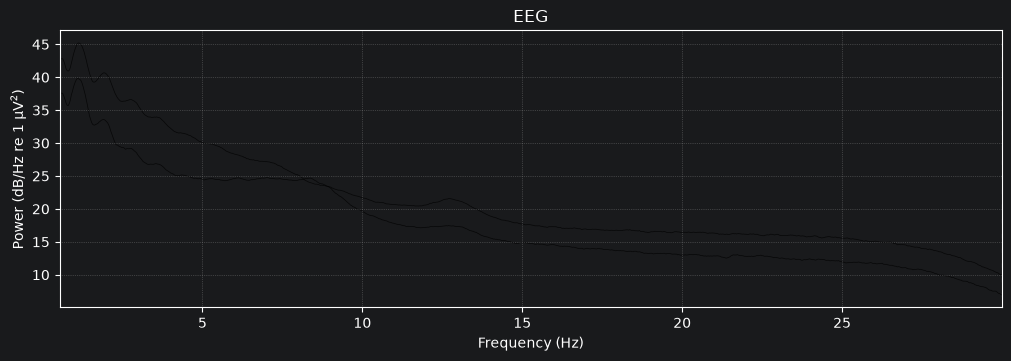

<Power Spectrum (from Epochs, multitaper method) | 1201 epochs × 2 channels × 885 freqs, 0.5-30.0 Hz>


In [216]:
psd_of_epochs = epochs.compute_psd(method='multitaper', fmin=0.5, fmax=30.0)
psd_of_epochs.plot()
print(psd_of_epochs)

In [217]:
psds, psd_frequencies = psd_of_epochs.get_data(return_freqs=True)
print("Shape of PSDs")
print("(30 second sections, channels, frequencies)")
print(psds.shape)

print("Shape of PSDs frequencies")
print(psd_frequencies.shape)

Shape of PSDs
(30 second sections, channels, frequencies)
(1201, 2, 885)
Shape of PSDs frequencies
(885,)


/var/folders/n_/8b4bszmd5vsdmpldt1bzw7jr0000gn/T/ipykernel_59824/4097291130.py:5: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  samples.compute_psd(method='multitaper', fmin=0.5, fmax=50).plot()


<Evoked | 'deep_sleep' (average, N=220), 0 – 30 s, baseline off, 2 ch, ~53 KiB>


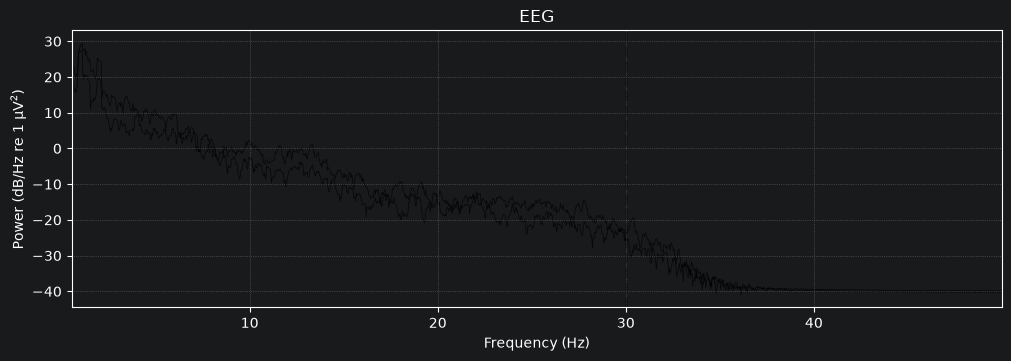

In [218]:
psd_plot(epochs["deep_sleep"].average())


<Evoked | 'awake' (average, N=548), 0 – 30 s, baseline off, 2 ch, ~53 KiB>


/var/folders/n_/8b4bszmd5vsdmpldt1bzw7jr0000gn/T/ipykernel_59824/4097291130.py:5: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  samples.compute_psd(method='multitaper', fmin=0.5, fmax=50).plot()


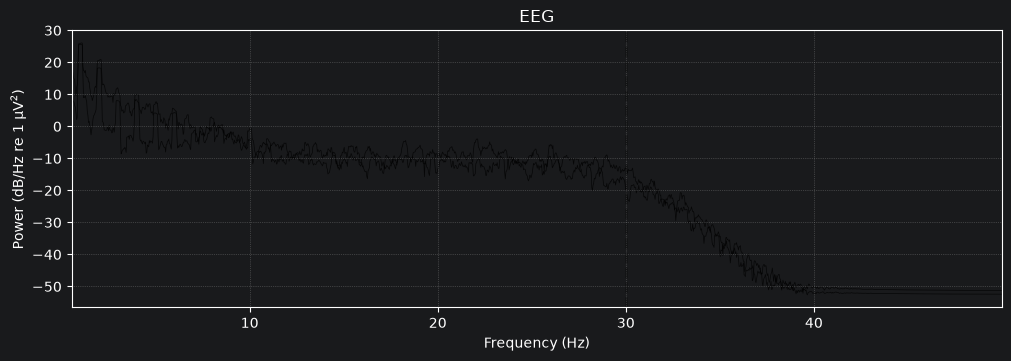

In [219]:
psd_plot(epochs["awake"].average())

<Evoked | 'rem' (average, N=125), 0 – 30 s, baseline off, 2 ch, ~53 KiB>


/var/folders/n_/8b4bszmd5vsdmpldt1bzw7jr0000gn/T/ipykernel_59824/4097291130.py:5: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  samples.compute_psd(method='multitaper', fmin=0.5, fmax=50).plot()


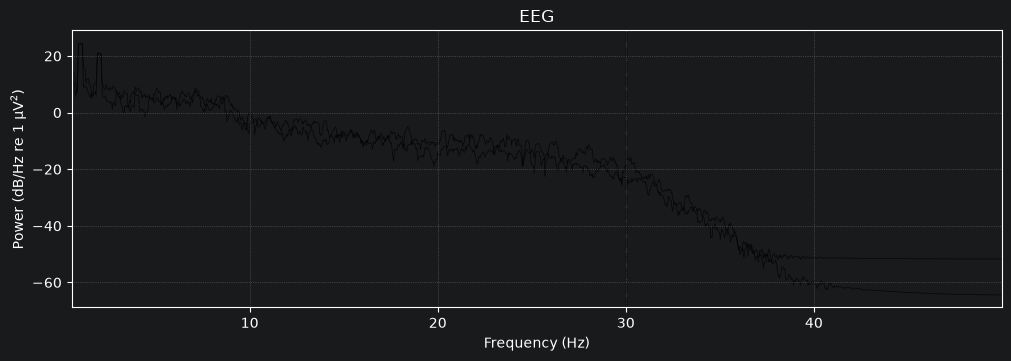

In [220]:
psd_plot(epochs["rem"].average())

<Evoked | 'light_sleep' (average, N=308), 0 – 30 s, baseline off, 2 ch, ~53 KiB>


/var/folders/n_/8b4bszmd5vsdmpldt1bzw7jr0000gn/T/ipykernel_59824/4097291130.py:5: RuntimeWarning: Channel locations not available. Disabling spatial colors.
  samples.compute_psd(method='multitaper', fmin=0.5, fmax=50).plot()


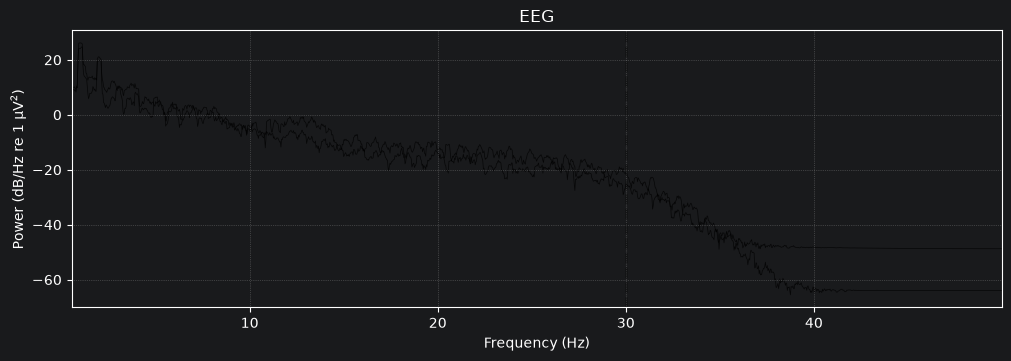

In [221]:
psd_plot(epochs["light_sleep"].average())

# Training the model

In [222]:
# Loading all of the participants epochs
all_epochs = []
for subject_index in range(2):
    raw_file = load_data(subject_index, 1)
    print("Raw file", str(subject_index),  "loaded")

    # Insert crop annotations subroutine

    events, event_id = create_events(raw_file)
    print("Events created from raw file", str(subject_index))

    epochs, epochs_train, labels = create_epochs(raw_file, events, event_id)
    print("Epoch", str(subject_index),  "created")

    all_epochs.append(epochs)



Raw file 0 loaded
Events created from raw file 0
Event labels array:
[1 1 1 ... 1 1 1]
Epoch 0 created
Raw file 1 loaded
Events created from raw file 1
Event labels array:
[1 1 1 ... 1 1 1]
Epoch 1 created


## Saving the Model

In [197]:

# Saving the model
"""
import joblib

joblib.dump(model, 'sleep_eeg_model.joblib')
"""

"\nimport joblib\n\njoblib.dump(model, 'sleep_eeg_model.joblib')\n"